In [2]:

from pathlib import Path
import gc
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

warnings.filterwarnings("default")

RANDOM_STATE = 42
TEST_SIZE = 0.20
CHUNK_SIZE = 200_000

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data" / "home_credit"
ARTIFACT_DIR = PROJECT_DIR / "artifacts"
RESULTS_DIR = PROJECT_DIR / "results"

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 80)

print("FinResilience AI - Notebook 1")
print("Project directory:", PROJECT_DIR.resolve())
print("Dataset directory:", DATA_DIR.resolve())
print("Random state:", RANDOM_STATE)


FinResilience AI - Notebook 1
Project directory: C:\mini_project
Dataset directory: C:\mini_project\data\home_credit
Random state: 42


In [3]:

REQUIRED_FILES = [
    "application_train.csv",
    "installments_payments.csv",
    "credit_card_balance.csv",
    "bureau.csv",
    "bureau_balance.csv",
]

OPTIONAL_FILES = [
    "previous_application.csv",
    "POS_CASH_balance.csv",
    "application_test.csv",
    "HomeCredit_columns_description.csv",
    "sample_submission.csv",
]

def find_file(filename):
    matches = list(DATA_DIR.rglob(filename)) if DATA_DIR.exists() else []
    return matches[0] if matches else None

file_paths = {
    name: find_file(name)
    for name in REQUIRED_FILES + OPTIONAL_FILES
}

file_status = pd.DataFrame([
    {
        "File": name,
        "Status": (
            "Found" if path else
            "MISSING - REQUIRED" if name in REQUIRED_FILES else
            "Optional file not found"
        ),
        "Path": str(path) if path else ""
    }
    for name, path in file_paths.items()
])

display(file_status)

missing_files = [
    name for name in REQUIRED_FILES
    if file_paths[name] is None
]

if missing_files:
    raise FileNotFoundError(
        "Required CSV files are missing: "
        + ", ".join(missing_files)
        + ". Place them inside data/home_credit/."
    )


,File,Status,Path
0,application_train.csv,Found,c:\mini_project\data\home_credit\application_train.csv
1,installments_payments.csv,Found,c:\mini_project\data\home_credit\installments_payments.csv
2,credit_card_balance.csv,Found,c:\mini_project\data\home_credit\credit_card_balance.csv
3,bureau.csv,Found,c:\mini_project\data\home_credit\bureau.csv
4,bureau_balance.csv,Found,c:\mini_project\data\home_credit\bureau_balance.csv
5,previous_application.csv,Found,c:\mini_project\data\home_credit\previous_application.csv
6,POS_CASH_balance.csv,Found,c:\mini_project\data\home_credit\POS_CASH_balance.csv
7,application_test.csv,Found,c:\mini_project\data\home_credit\application_test.csv
8,HomeCredit_columns_description.csv,Found,c:\mini_project\data\home_credit\HomeCredit_columns_description.csv
9,sample_submission.csv,Found,c:\mini_project\data\home_credit\sample_submission.csv


Dataset shape: (307511, 122)
Unique applicants: 307511
Duplicate rows: 0


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,...,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,...,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,...,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,-815.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008019,-19005,-3039,-9833.0,-2437,NaN,1,1,0,1,0,0,Laborers,2.0,2,2,WEDNESDAY,17,0,0,0,0,0,0,Business Entity Type 3,NaN,0.650442,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,0.0,2.0,0.0,-617.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,Working,Secondary / secondary special,Single /

,Column count
float64,65
int64,41
str,16


,Count,Percentage
TARGET,,
0,282686,91.93
1,24825,8.07


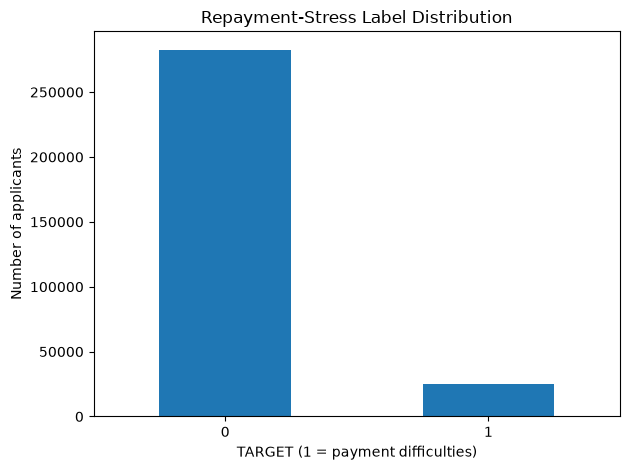

In [4]:

application = pd.read_csv(
    file_paths["application_train.csv"],
    low_memory=False
)

if "SK_ID_CURR" not in application.columns:
    raise ValueError("SK_ID_CURR is missing from application_train.csv.")

if "TARGET" not in application.columns:
    raise ValueError("TARGET is missing from application_train.csv.")

if application["SK_ID_CURR"].duplicated().any():
    raise ValueError("Duplicate applicant IDs found in application_train.csv.")

if application["TARGET"].isna().any():
    raise ValueError("Missing TARGET labels found.")

if not set(application["TARGET"].unique()).issubset({0, 1}):
    raise ValueError("TARGET must contain only 0 and 1.")

print("Dataset shape:", application.shape)
print("Unique applicants:", application["SK_ID_CURR"].nunique())
print("Duplicate rows:", application.duplicated().sum())

display(application.head())
display(application.dtypes.astype(str).value_counts().to_frame("Column count"))

target_summary = pd.DataFrame({
    "Count": application["TARGET"].value_counts().sort_index(),
    "Percentage": (
        application["TARGET"].value_counts(normalize=True).sort_index() * 100
    ).round(2)
})

display(target_summary)

ax = application["TARGET"].value_counts().sort_index().plot(
    kind="bar", rot=0
)
ax.set_title("Repayment-Stress Label Distribution")
ax.set_xlabel("TARGET (1 = payment difficulties)")
ax.set_ylabel("Number of applicants")
plt.tight_layout()
plt.show()

target_summary.to_csv(
    RESULTS_DIR / "target_distribution.csv"
)

In [5]:

missing_summary = pd.DataFrame({
    "Missing Count": application.isna().sum(),
    "Missing Percentage": (
        application.isna().mean() * 100
    ).round(2),
    "Data Type": application.dtypes.astype(str)
}).sort_values("Missing Percentage", ascending=False)

display(missing_summary.head(30))

missing_summary.to_csv(
    RESULTS_DIR / "application_missingness.csv"
)

numeric_columns = application.select_dtypes(
    include=np.number
).columns

display(application[numeric_columns].describe().T.head(30))


,Missing Count,Missing Percentage,Data Type
COMMONAREA_AVG,214865,69.87,float64
COMMONAREA_MODE,214865,69.87,float64
COMMONAREA_MEDI,214865,69.87,float64
NONLIVINGAPARTMENTS_MEDI,213514,69.43,float64
NONLIVINGAPARTMENTS_MODE,213514,69.43,float64
NONLIVINGAPARTMENTS_AVG,213514,69.43,float64
FONDKAPREMONT_MODE,210295,68.39,str
LIVINGAPARTMENTS_AVG,210199,68.35,float64
LIVINGAPARTMENTS_MEDI,210199,68.35,float64
LIVINGAPARTMENTS_MODE,210199,68.35,float64


,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,278180.518577,102790.175348,100002.000000,189145.500000,278202.000000,367142.500000,4.562550e+05
TARGET,307511.0,0.080729,0.272419,0.000000,0.000000,0.000000,0.000000,1.000000e+00
CNT_CHILDREN,307511.0,0.417052,0.722121,0.000000,0.000000,0.000000,1.000000,1.900000e+01
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.000000,112500.000000,147150.000000,202500.000000,1.170000e+08
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.000000,270000.000000,513531.000000,808650.000000,4.050000e+06
AMT_ANNUITY,307499.0,27108.573909,14493.737315,1615.500000,16524.000000,24903.000000,34596.000000,2.580255e+05
AMT_GOODS_PRICE,307233.0,538396.207429,369446.460540,40500.000000,238500.000000,450000.000000,679500.000000,4.050000e+06
REGION_POPULATION_RELATIVE,307511.0,0.020868,0.013831,0.000290,0.010006,0.018850,0.028663,7.250800e-02
DAYS_BIRTH,307511.0,-16036.995067,4363.988632,-25229.000000,-19682.000000,-15750.000000,-12413.000000,-7.489000e+03
DAYS_EMPLOYED,307511.0,63815.045904,141275.766519,-17912.000000,-2760.000000,-1213.000000,-289.000000,3.652430e+05


In [6]:

def safe_ratio(numerator, denominator):
    denominator = denominator.replace(0, np.nan)
    result = numerator / denominator
    return result.replace([np.inf, -np.inf], np.nan)


def build_group_a(data):
    numeric_candidates = [
        "AMT_INCOME_TOTAL",
        "AMT_CREDIT",
        "AMT_ANNUITY",
        "AMT_GOODS_PRICE",
        "DAYS_EMPLOYED",
        "CNT_FAM_MEMBERS",
        "CNT_CHILDREN",
        "REGION_POPULATION_RELATIVE",
        "OWN_CAR_AGE",
        "HOUR_APPR_PROCESS_START",
        "REGION_RATING_CLIENT",
        "REGION_RATING_CLIENT_W_CITY",
        "FLAG_OWN_CAR",
        "FLAG_OWN_REALTY",
    ]

    categorical_candidates = [
        "NAME_CONTRACT_TYPE",
        "NAME_INCOME_TYPE",
        "NAME_EDUCATION_TYPE",
        "NAME_FAMILY_STATUS",
        "NAME_HOUSING_TYPE",
        "OCCUPATION_TYPE",
        "WEEKDAY_APPR_PROCESS_START",
        "ORGANIZATION_TYPE",
    ]

    numeric_features = [
        col for col in numeric_candidates
        if col in data.columns
    ]

    categorical_features = [
        col for col in categorical_candidates
        if col in data.columns
    ]

    features = data[
        numeric_features + categorical_features
    ].copy()

    if {"AMT_ANNUITY", "AMT_INCOME_TOTAL"}.issubset(data.columns):
        features["EMI_BURDEN"] = safe_ratio(
            data["AMT_ANNUITY"],
            data["AMT_INCOME_TOTAL"]
        )

    if {"AMT_CREDIT", "AMT_INCOME_TOTAL"}.issubset(data.columns):
        features["CREDIT_TO_INCOME"] = safe_ratio(
            data["AMT_CREDIT"],
            data["AMT_INCOME_TOTAL"]
        )

    if "DAYS_EMPLOYED" in features.columns:
        features["EMPLOYMENT_DAYS_SENTINEL"] = (
            features["DAYS_EMPLOYED"] == 365243
        ).astype("int8")

        features.loc[
            features["DAYS_EMPLOYED"] == 365243,
            "DAYS_EMPLOYED"
        ] = np.nan

    return features


group_a = build_group_a(application)

print("Group A shape:", group_a.shape)
print("Group A columns:")
print(group_a.columns.tolist())

display(group_a.head())


Group A shape: (307511, 25)
Group A columns:
['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'DAYS_EMPLOYED', 'CNT_FAM_MEMBERS', 'CNT_CHILDREN', 'REGION_POPULATION_RELATIVE', 'OWN_CAR_AGE', 'HOUR_APPR_PROCESS_START', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_CONTRACT_TYPE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'EMI_BURDEN', 'CREDIT_TO_INCOME', 'EMPLOYMENT_DAYS_SENTINEL']


,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,DAYS_EMPLOYED,CNT_FAM_MEMBERS,CNT_CHILDREN,REGION_POPULATION_RELATIVE,OWN_CAR_AGE,HOUR_APPR_PROCESS_START,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_CONTRACT_TYPE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,OCCUPATION_TYPE,WEEKDAY_APPR_PROCESS_START,ORGANIZATION_TYPE,EMI_BURDEN,CREDIT_TO_INCOME,EMPLOYMENT_DAYS_SENTINEL
0,202500.0,406597.5,24700.5,351000.0,-637.0,1.0,0,0.018801,NaN,10,2,2,N,Y,Cash loans,Working,Secondary / secondary special,Single / not married,House / apartment,Laborers,WEDNESDAY,Business Entity Type 3,0.121978,2.007889,0
1,270000.0,1293502.5,35698.5,1129500.0,-1188.0,2.0,0,0.003541,NaN,11,1,1,N,N,Cash loans,State servant,Higher education,Married,House / apartment,Core staff,MONDAY,School,0.132217,4.790750,0
2,67500.0,135000.0,6750.0,135000.0,-225.0,1.0,0,0.010032,26.0,9,2,2,Y,Y,Revolving loans,Working,Secondary / secondary special,Single / not married,House / apartment,Laborers,MONDAY,Government,0.100000,2.000000,0
3,135000.0,312682.5,29686.5,297000.0,-3039.0,2.0,0,0.008019,NaN,17,2,2,N,Y,Cash loans,Working,Secondary / secondary special,Civil marriage,House / apartment,Laborers,WEDNESDAY,Business Entity Type 3,0.219900,2.316167,0
4,121500.0,513000.0,21865.5,513000.0,-3038.0,1.0,0,0.028663,NaN,11,2,2,N,Y,Cash loans,Working,Secondary / secondary special,Single / not married,House / apartment,Core staff,THURSDAY,Religion,0.179963,4.222222,0


In [7]:

def aggregate_installments(path):
    columns = pd.read_csv(path, nrows=0).columns.tolist()

    required = [
        "SK_ID_CURR",
        "AMT_INSTALMENT",
        "AMT_PAYMENT",
    ]

    missing = [c for c in required if c not in columns]
    if missing:
        raise ValueError(
            f"Installment table is missing columns: {missing}"
        )

    usecols = required + [
        c for c in [
            "DAYS_INSTALMENT",
            "DAYS_ENTRY_PAYMENT",
        ] if c in columns
    ]

    partial_results = []

    for chunk in pd.read_csv(
        path,
        usecols=usecols,
        chunksize=CHUNK_SIZE,
        low_memory=False
    ):
        instalment = chunk["AMT_INSTALMENT"]
        payment = chunk["AMT_PAYMENT"]

        valid_instalment = instalment.notna() & (instalment > 0)

        chunk["PAYMENT_RATIO"] = np.where(
            valid_instalment,
            payment / instalment,
            np.nan
        )

        chunk["UNDERPAID"] = (
            payment < instalment
        ).where(
            payment.notna() & instalment.notna()
        ).astype(float)

        if "DAYS_INSTALMENT" in chunk.columns:
            days = chunk["DAYS_INSTALMENT"]

            if "DAYS_ENTRY_PAYMENT" in chunk.columns:
                entry_days = chunk["DAYS_ENTRY_PAYMENT"]

                chunk["DAYS_LATE"] = (
                    entry_days - days
                ).clip(lower=0)

                chunk.loc[
                    entry_days.isna() | days.isna(),
                    "DAYS_LATE"
                ] = np.nan
            else:
                chunk["DAYS_LATE"] = np.nan

            # Relative days are negative for historical records.
            chunk["RECENT_6M"] = (
                days.between(-183, 0)
            ).astype("int8")

            chunk["RECENT_12M"] = (
                days.between(-365, 0)
            ).astype("int8")

            chunk["UNDERPAID_6M"] = (
                chunk["UNDERPAID"] * chunk["RECENT_6M"]
            )

            chunk["UNDERPAID_12M"] = (
                chunk["UNDERPAID"] * chunk["RECENT_12M"]
            )
        else:
            chunk["DAYS_LATE"] = np.nan
            chunk["RECENT_6M"] = 0
            chunk["RECENT_12M"] = 0
            chunk["UNDERPAID_6M"] = 0.0
            chunk["UNDERPAID_12M"] = 0.0

        chunk["LATE_PAYMENT"] = (
            chunk["DAYS_LATE"] > 0
        ).astype(float)

        chunk["RATIO_SQUARED"] = chunk["PAYMENT_RATIO"] ** 2

        grouped = chunk.groupby("SK_ID_CURR").agg(
            RATIO_SUM=("PAYMENT_RATIO", "sum"),
            RATIO_COUNT=("PAYMENT_RATIO", "count"),
            RATIO_SQ_SUM=("RATIO_SQUARED", "sum"),
            RATIO_MAX=("PAYMENT_RATIO", "max"),
            UNDERPAID_SUM=("UNDERPAID", "sum"),
            INSTALLMENT_COUNT=("UNDERPAID", "count"),
            LATE_DAYS_SUM=("DAYS_LATE", "sum"),
            LATE_DAYS_COUNT=("DAYS_LATE", "count"),
            LATE_DAYS_MAX=("DAYS_LATE", "max"),
            LATE_COUNT=("LATE_PAYMENT", "sum"),
            RECENT_6M_COUNT=("RECENT_6M", "sum"),
            RECENT_12M_COUNT=("RECENT_12M", "sum"),
            UNDERPAID_6M_SUM=("UNDERPAID_6M", "sum"),
            UNDERPAID_12M_SUM=("UNDERPAID_12M", "sum"),
        )

        partial_results.append(grouped)
        del chunk, grouped
        gc.collect()

    combined = pd.concat(partial_results)

    # Combine chunk-level sufficient statistics.
    additive_columns = [
        "RATIO_SUM", "RATIO_COUNT", "RATIO_SQ_SUM",
        "UNDERPAID_SUM", "INSTALLMENT_COUNT",
        "LATE_DAYS_SUM", "LATE_DAYS_COUNT", "LATE_COUNT",
        "RECENT_6M_COUNT", "RECENT_12M_COUNT",
        "UNDERPAID_6M_SUM", "UNDERPAID_12M_SUM",
    ]

    result = combined.groupby(level=0)[additive_columns].sum()
    result["RATIO_MAX"] = combined.groupby(level=0)["RATIO_MAX"].max()
    result["LATE_DAYS_MAX"] = combined.groupby(level=0)["LATE_DAYS_MAX"].max()

    result["INST_PAYMENT_RATIO_MEAN"] = (
        result["RATIO_SUM"] / result["RATIO_COUNT"].replace(0, np.nan)
    )

    variance = (
        result["RATIO_SQ_SUM"] / result["RATIO_COUNT"].replace(0, np.nan)
        - result["INST_PAYMENT_RATIO_MEAN"] ** 2
    ).clip(lower=0)

    result["INST_PAYMENT_RATIO_STD"] = np.sqrt(variance)

    result["INST_UNDERPAID_SHARE"] = (
        result["UNDERPAID_SUM"]
        / result["INSTALLMENT_COUNT"].replace(0, np.nan)
    )

    result["INST_MEAN_DAYS_LATE"] = (
        result["LATE_DAYS_SUM"]
        / result["LATE_DAYS_COUNT"].replace(0, np.nan)
    )

    result["INST_LATE_PAYMENT_SHARE"] = (
        result["LATE_COUNT"]
        / result["LATE_DAYS_COUNT"].replace(0, np.nan)
    )

    result["INST_UNDERPAID_SHARE_6M"] = (
        result["UNDERPAID_6M_SUM"]
        / result["RECENT_6M_COUNT"].replace(0, np.nan)
    )

    result["INST_UNDERPAID_SHARE_12M"] = (
        result["UNDERPAID_12M_SUM"]
        / result["RECENT_12M_COUNT"].replace(0, np.nan)
    )

    result["HAS_INSTALLMENT_HISTORY"] = 1

    result = result.drop(columns=[
        "RATIO_SUM", "RATIO_COUNT", "RATIO_SQ_SUM",
        "UNDERPAID_SUM", "INSTALLMENT_COUNT",
        "LATE_DAYS_SUM", "LATE_DAYS_COUNT", "LATE_COUNT",
        "RECENT_6M_COUNT", "RECENT_12M_COUNT",
        "UNDERPAID_6M_SUM", "UNDERPAID_12M_SUM",
    ])

    return result.reset_index(names="SK_ID_CURR")


installments = aggregate_installments(
    file_paths["installments_payments.csv"]
)

print("Installment aggregate shape:", installments.shape)
display(installments.head())

installments.to_csv(
    ARTIFACT_DIR / "installments_aggregated.csv",
    index=False
)


Installment aggregate shape: (339587, 11)


,SK_ID_CURR,RATIO_MAX,LATE_DAYS_MAX,INST_PAYMENT_RATIO_MEAN,INST_PAYMENT_RATIO_STD,INST_UNDERPAID_SHARE,INST_MEAN_DAYS_LATE,INST_LATE_PAYMENT_SHARE,INST_UNDERPAID_SHARE_6M,INST_UNDERPAID_SHARE_12M,HAS_INSTALLMENT_HISTORY
0,100001,1.0,11.0,1.0,0.0,0.0,1.571429,0.142857,NaN,NaN,1
1,100002,1.0,0.0,1.0,0.0,0.0,0.000000,0.000000,0.0,0.0,1
2,100003,1.0,0.0,1.0,0.0,0.0,0.000000,0.000000,NaN,NaN,1
3,100004,1.0,0.0,1.0,0.0,0.0,0.000000,0.000000,NaN,NaN,1
4,100005,1.0,1.0,1.0,0.0,0.0,0.111111,0.111111,NaN,NaN,1


In [8]:

def aggregate_credit_card(path):
    columns = pd.read_csv(path, nrows=0).columns.tolist()

    required = [
        "SK_ID_CURR",
        "AMT_BALANCE",
        "AMT_CREDIT_LIMIT_ACTUAL",
    ]

    missing = [c for c in required if c not in columns]
    if missing:
        raise ValueError(
            f"Credit-card table is missing columns: {missing}"
        )

    usecols = required + [
        c for c in [
            "MONTHS_BALANCE",
        ] if c in columns
    ]

    df = pd.read_csv(
        path,
        usecols=usecols,
        low_memory=False
    )

    limit = df["AMT_CREDIT_LIMIT_ACTUAL"].replace(0, np.nan)

    df["CC_UTILISATION"] = (
        df["AMT_BALANCE"] / limit
    ).replace([np.inf, -np.inf], np.nan)

    result = df.groupby("SK_ID_CURR").agg(
        CC_BALANCE_MEAN=("AMT_BALANCE", "mean"),
        CC_BALANCE_MAX=("AMT_BALANCE", "max"),
        CC_UTILISATION_MEAN=("CC_UTILISATION", "mean"),
        CC_UTILISATION_MAX=("CC_UTILISATION", "max"),
        CC_LIMIT_MEAN=("AMT_CREDIT_LIMIT_ACTUAL", "mean"),
    )

    # Compute utilisation trend from applicant-level monthly observations.
    if "MONTHS_BALANCE" in df.columns:
        monthly = df.groupby(
            ["SK_ID_CURR", "MONTHS_BALANCE"],
            as_index=False
        )["CC_UTILISATION"].mean()

        monthly = monthly.dropna(
            subset=["MONTHS_BALANCE", "CC_UTILISATION"]
        )

        monthly["X"] = monthly["MONTHS_BALANCE"].astype(float)
        monthly["Y"] = monthly["CC_UTILISATION"]
        monthly["XY"] = monthly["X"] * monthly["Y"]
        monthly["X2"] = monthly["X"] ** 2

        sums = monthly.groupby("SK_ID_CURR").agg(
            N=("X", "count"),
            SX=("X", "sum"),
            SY=("Y", "sum"),
            SXY=("XY", "sum"),
            SX2=("X2", "sum"),
        )

        denominator = sums["N"] * sums["SX2"] - sums["SX"] ** 2

        sums["CC_UTILISATION_TREND"] = (
            sums["N"] * sums["SXY"] - sums["SX"] * sums["SY"]
        ) / denominator.replace(0, np.nan)

        result = result.join(
            sums[["CC_UTILISATION_TREND"]],
            how="left"
        )

    result["HAS_CREDIT_CARD_HISTORY"] = 1

    del df
    gc.collect()

    return result.reset_index()


credit_card = aggregate_credit_card(
    file_paths["credit_card_balance.csv"]
)

print("Credit-card aggregate shape:", credit_card.shape)
display(credit_card.head())

credit_card.to_csv(
    ARTIFACT_DIR / "credit_card_aggregated.csv",
    index=False
)


Credit-card aggregate shape: (103558, 8)


,SK_ID_CURR,CC_BALANCE_MEAN,CC_BALANCE_MAX,CC_UTILISATION_MEAN,CC_UTILISATION_MAX,CC_LIMIT_MEAN,CC_UTILISATION_TREND,HAS_CREDIT_CARD_HISTORY
0,100006,0.000000,0.00,0.000000,0.00000,270000.000000,0.000000,1
1,100011,54482.111149,189000.00,0.302678,1.05000,164189.189189,-0.015862,1
2,100013,18159.919219,161420.22,0.115301,1.02489,131718.750000,-0.004688,1
3,100021,0.000000,0.00,0.000000,0.00000,675000.000000,0.000000,1
4,100023,0.000000,0.00,0.000000,0.00000,135000.000000,0.000000,1


In [9]:
def aggregate_bureau(bureau_path, balance_path):
    bureau_columns = pd.read_csv(
        bureau_path, nrows=0
    ).columns.tolist()

    required = [
        "SK_ID_CURR",
        "SK_ID_BUREAU",
        "CREDIT_ACTIVE",
        "AMT_CREDIT_SUM",
        "AMT_CREDIT_SUM_DEBT",
    ]

    missing = [
        c for c in required if c not in bureau_columns
    ]

    if missing:
        raise ValueError(
            f"Bureau table is missing columns: {missing}"
        )

    optional = [
        c for c in [
            "CREDIT_DAY_OVERDUE",
            "DAYS_CREDIT",
        ] if c in bureau_columns
    ]

    bureau = pd.read_csv(
        bureau_path,
        usecols=required + optional,
        low_memory=False
    )

    bureau["ACTIVE_CREDIT_FLAG"] = (
        bureau["CREDIT_ACTIVE"] == "Active"
    ).astype("int8")

    if "CREDIT_DAY_OVERDUE" in bureau.columns:
        bureau["OVERDUE_FLAG"] = (
            bureau["CREDIT_DAY_OVERDUE"] > 0
        ).astype("int8")
    else:
        bureau["OVERDUE_FLAG"] = 0

    aggregations = {
        "AMT_CREDIT_SUM": ["sum", "mean"],
        "AMT_CREDIT_SUM_DEBT": ["sum", "mean"],
        "ACTIVE_CREDIT_FLAG": ["sum", "mean"],
        "OVERDUE_FLAG": ["sum", "mean"],
    }

    if "CREDIT_DAY_OVERDUE" in bureau.columns:
        aggregations["CREDIT_DAY_OVERDUE"] = ["mean", "max"]

    if "DAYS_CREDIT" in bureau.columns:
        aggregations["DAYS_CREDIT"] = ["min", "max"]

    result = bureau.groupby("SK_ID_CURR").agg(aggregations)
    result.columns = [
        "BURO_" + "_".join(col).upper()
        for col in result.columns
    ]
    result = result.reset_index()

    result["HAS_BUREAU_HISTORY"] = 1

    # Aggregate monthly bureau-balance status by bureau account.
    balance_columns = pd.read_csv(
        balance_path, nrows=0
    ).columns.tolist()

    if {"SK_ID_BUREAU", "STATUS"}.issubset(balance_columns):
        balance = pd.read_csv(
            balance_path,
            usecols=["SK_ID_BUREAU", "STATUS"],
            low_memory=False
        )

        # Statuses 1-5 indicate progressively serious overdue states.
        balance["OVERDUE_MONTH"] = (
            balance["STATUS"].astype(str).isin(
                ["1", "2", "3", "4", "5"]
            )
        ).astype("int8")

        balance_summary = balance.groupby("SK_ID_BUREAU").agg(
            OVERDUE_MONTH_SHARE=("OVERDUE_MONTH", "mean"),
            OBSERVED_MONTHS=("STATUS", "size"),
        ).reset_index()

        bureau_mapping = bureau[
            ["SK_ID_CURR", "SK_ID_BUREAU"]
        ].drop_duplicates()

        joined = bureau_mapping.merge(
            balance_summary,
            on="SK_ID_BUREAU",
            how="left",
            validate="many_to_one"
        )

        applicant_summary = joined.groupby("SK_ID_CURR").agg(
            BURO_BALANCE_OVERDUE_MONTH_SHARE=(
                "OVERDUE_MONTH_SHARE", "mean"
            ),
            BURO_BALANCE_OBSERVED_MONTHS=(
                "OBSERVED_MONTHS", "sum"
            ),
        ).reset_index()

        result = result.merge(
            applicant_summary,
            on="SK_ID_CURR",
            how="left",
            validate="one_to_one"
        )

        del balance, balance_summary, joined, applicant_summary
        gc.collect()

    del bureau
    gc.collect()

    return result


bureau = aggregate_bureau(
    file_paths["bureau.csv"],
    file_paths["bureau_balance.csv"]
)

print("Bureau aggregate shape:", bureau.shape)
display(bureau.head())

bureau.to_csv(
    ARTIFACT_DIR / "bureau_aggregated.csv",
    index=False
)


Bureau aggregate shape: (305811, 16)


,SK_ID_CURR,BURO_AMT_CREDIT_SUM_SUM,BURO_AMT_CREDIT_SUM_MEAN,BURO_AMT_CREDIT_SUM_DEBT_SUM,BURO_AMT_CREDIT_SUM_DEBT_MEAN,BURO_ACTIVE_CREDIT_FLAG_SUM,BURO_ACTIVE_CREDIT_FLAG_MEAN,BURO_OVERDUE_FLAG_SUM,BURO_OVERDUE_FLAG_MEAN,BURO_CREDIT_DAY_OVERDUE_MEAN,BURO_CREDIT_DAY_OVERDUE_MAX,BURO_DAYS_CREDIT_MIN,BURO_DAYS_CREDIT_MAX,HAS_BUREAU_HISTORY,BURO_BALANCE_OVERDUE_MONTH_SHARE,BURO_BALANCE_OBSERVED_MONTHS
0,100001,1453365.000,207623.571429,596686.5,85240.928571,3,0.428571,0,0.0,0.0,0,-1572,-49,1,0.007519,172.0
1,100002,865055.565,108131.945625,245781.0,49156.200000,2,0.250000,0,0.0,0.0,0,-1437,-103,1,0.255682,110.0
2,100003,1017400.500,254350.125000,0.0,0.000000,1,0.250000,0,0.0,0.0,0,-2586,-606,1,NaN,0.0
3,100004,189037.800,94518.900000,0.0,0.000000,0,0.000000,0,0.0,0.0,0,-1326,-408,1,NaN,0.0
4,100005,657126.000,219042.000000,568408.5,189469.500000,2,0.666667,0,0.0,0.0,0,-373,-62,1,0.000000,21.0


In [10]:

# Combine all applicant-level behavioural aggregates.
group_b = installments.merge(
    credit_card,
    on="SK_ID_CURR",
    how="outer",
    validate="one_to_one"
)

group_b = group_b.merge(
    bureau,
    on="SK_ID_CURR",
    how="outer",
    validate="one_to_one"
)

# Convert absent linked-history records into explicit history flags.
history_flags = [
    "HAS_INSTALLMENT_HISTORY",
    "HAS_CREDIT_CARD_HISTORY",
    "HAS_BUREAU_HISTORY",
]

for flag in history_flags:
    if flag not in group_b.columns:
        group_b[flag] = 0
    else:
        group_b[flag] = group_b[flag].fillna(0).astype("int8")

print("Group B shape:", group_b.shape)
print("Group B columns:")
print(group_b.columns.tolist())

display(group_b.head())

group_b.to_csv(
    ARTIFACT_DIR / "home_credit_group_b.csv",
    index=False
)


Group B shape: (353739, 33)
Group B columns:
['SK_ID_CURR', 'RATIO_MAX', 'LATE_DAYS_MAX', 'INST_PAYMENT_RATIO_MEAN', 'INST_PAYMENT_RATIO_STD', 'INST_UNDERPAID_SHARE', 'INST_MEAN_DAYS_LATE', 'INST_LATE_PAYMENT_SHARE', 'INST_UNDERPAID_SHARE_6M', 'INST_UNDERPAID_SHARE_12M', 'HAS_INSTALLMENT_HISTORY', 'CC_BALANCE_MEAN', 'CC_BALANCE_MAX', 'CC_UTILISATION_MEAN', 'CC_UTILISATION_MAX', 'CC_LIMIT_MEAN', 'CC_UTILISATION_TREND', 'HAS_CREDIT_CARD_HISTORY', 'BURO_AMT_CREDIT_SUM_SUM', 'BURO_AMT_CREDIT_SUM_MEAN', 'BURO_AMT_CREDIT_SUM_DEBT_SUM', 'BURO_AMT_CREDIT_SUM_DEBT_MEAN', 'BURO_ACTIVE_CREDIT_FLAG_SUM', 'BURO_ACTIVE_CREDIT_FLAG_MEAN', 'BURO_OVERDUE_FLAG_SUM', 'BURO_OVERDUE_FLAG_MEAN', 'BURO_CREDIT_DAY_OVERDUE_MEAN', 'BURO_CREDIT_DAY_OVERDUE_MAX', 'BURO_DAYS_CREDIT_MIN', 'BURO_DAYS_CREDIT_MAX', 'HAS_BUREAU_HISTORY', 'BURO_BALANCE_OVERDUE_MONTH_SHARE', 'BURO_BALANCE_OBSERVED_MONTHS']


,SK_ID_CURR,RATIO_MAX,LATE_DAYS_MAX,INST_PAYMENT_RATIO_MEAN,INST_PAYMENT_RATIO_STD,INST_UNDERPAID_SHARE,INST_MEAN_DAYS_LATE,INST_LATE_PAYMENT_SHARE,INST_UNDERPAID_SHARE_6M,INST_UNDERPAID_SHARE_12M,HAS_INSTALLMENT_HISTORY,CC_BALANCE_MEAN,CC_BALANCE_MAX,CC_UTILISATION_MEAN,CC_UTILISATION_MAX,CC_LIMIT_MEAN,CC_UTILISATION_TREND,HAS_CREDIT_CARD_HISTORY,BURO_AMT_CREDIT_SUM_SUM,BURO_AMT_CREDIT_SUM_MEAN,BURO_AMT_CREDIT_SUM_DEBT_SUM,BURO_AMT_CREDIT_SUM_DEBT_MEAN,BURO_ACTIVE_CREDIT_FLAG_SUM,BURO_ACTIVE_CREDIT_FLAG_MEAN,BURO_OVERDUE_FLAG_SUM,BURO_OVERDUE_FLAG_MEAN,BURO_CREDIT_DAY_OVERDUE_MEAN,BURO_CREDIT_DAY_OVERDUE_MAX,BURO_DAYS_CREDIT_MIN,BURO_DAYS_CREDIT_MAX,HAS_BUREAU_HISTORY,BURO_BALANCE_OVERDUE_MONTH_SHARE,BURO_BALANCE_OBSERVED_MONTHS
0,100001,1.0,11.0,1.0,0.0,0.0,1.571429,0.142857,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,0,1453365.000,207623.571429,596686.5,85240.928571,3.0,0.428571,0.0,0.0,0.0,0.0,-1572.0,-49.0,1,0.007519,172.0
1,100002,1.0,0.0,1.0,0.0,0.0,0.000000,0.000000,0.0,0.0,1,NaN,NaN,NaN,NaN,NaN,NaN,0,865055.565,108131.945625,245781.0,49156.200000,2.0,0.250000,0.0,0.0,0.0,0.0,-1437.0,-103.0,1,0.255682,110.0
2,100003,1.0,0.0,1.0,0.0,0.0,0.000000,0.000000,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,0,1017400.500,254350.125000,0.0,0.000000,1.0,0.250000,0.0,0.0,0.0,0.0,-2586.0,-606.0,1,NaN,0.0
3,100004,1.0,0.0,1.0,0.0,0.0,0.000000,0.000000,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,0,189037.800,94518.900000,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,-1326.0,-408.0,1,NaN,0.0
4,100005,1.0,1.0,1.0,0.0,0.0,0.111111,0.111111,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,0,657126.000,219042.000000,568408.5,189469.500000,2.0,0.666667,0.0,0.0,0.0,0.0,-373.0,-62.0,1,0.000000,21.0


In [11]:
target = application["TARGET"].astype("int8").copy()
applicant_ids = application["SK_ID_CURR"].copy()

# Retain gender and age only for the later fairness audit.
audit_columns = [
    c for c in ["SK_ID_CURR", "CODE_GENDER", "DAYS_BIRTH"]
    if c in application.columns
]

audit_data = application[audit_columns].copy()

# Exclude any EXT_SOURCE fields from the main Group A feature set.
group_a_model = group_a.loc[
    :,
    [c for c in group_a.columns if not c.startswith("EXT_SOURCE")]
].copy()

# Keep the same applicant order throughout assembly.
if not np.array_equal(
    group_a_model.index.to_numpy(),
    application.index.to_numpy()
):
    raise ValueError("Group A row order does not match application data.")

group_b_aligned = applicant_ids.to_frame().merge(
    group_b,
    on="SK_ID_CURR",
    how="left",
    validate="one_to_one"
)

feature_table = pd.concat(
    [
        applicant_ids.reset_index(drop=True).rename("SK_ID_CURR"),
        target.reset_index(drop=True).rename("TARGET"),
        group_a_model.reset_index(drop=True),
        group_b_aligned.drop(
            columns=["SK_ID_CURR"]
        ).reset_index(drop=True),
    ],
    axis=1
)

# Data integrity checks.
if feature_table["SK_ID_CURR"].duplicated().any():
    raise ValueError("Duplicate applicant IDs in final feature table.")

if feature_table["TARGET"].isna().any():
    raise ValueError("Missing target values in final feature table.")

if feature_table.columns.duplicated().any():
    duplicates = feature_table.columns[
        feature_table.columns.duplicated()
    ].tolist()
    raise ValueError(f"Duplicate column names: {duplicates}")

# Check for infinite numeric feature values.
numeric_features = feature_table.select_dtypes(
    include=np.number
).columns.drop(["SK_ID_CURR", "TARGET"], errors="ignore")

infinite_counts = np.isinf(
    feature_table[numeric_features]
).sum().sum()

print("Final feature table shape:", feature_table.shape)
print("Duplicate applicant IDs:", feature_table["SK_ID_CURR"].duplicated().sum())
print("Infinite feature values:", int(infinite_counts))
print("Group A feature count:", len(group_a_model.columns))
print("Group B feature count:", len(group_b.columns) - 1)

display(feature_table.head())

feature_table.to_csv(
    ARTIFACT_DIR / "home_credit_feature_table.csv",
    index=False
)

audit_data.to_csv(
    ARTIFACT_DIR / "home_credit_audit_columns.csv",
    index=False
)


Final feature table shape: (307511, 59)
Duplicate applicant IDs: 0
Infinite feature values: 0
Group A feature count: 25
Group B feature count: 32


,SK_ID_CURR,TARGET,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,DAYS_EMPLOYED,CNT_FAM_MEMBERS,CNT_CHILDREN,REGION_POPULATION_RELATIVE,OWN_CAR_AGE,HOUR_APPR_PROCESS_START,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_CONTRACT_TYPE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,OCCUPATION_TYPE,WEEKDAY_APPR_PROCESS_START,ORGANIZATION_TYPE,EMI_BURDEN,CREDIT_TO_INCOME,EMPLOYMENT_DAYS_SENTINEL,RATIO_MAX,LATE_DAYS_MAX,INST_PAYMENT_RATIO_MEAN,INST_PAYMENT_RATIO_STD,INST_UNDERPAID_SHARE,INST_MEAN_DAYS_LATE,INST_LATE_PAYMENT_SHARE,INST_UNDERPAID_SHARE_6M,INST_UNDERPAID_SHARE_12M,HAS_INSTALLMENT_HISTORY,CC_BALANCE_MEAN,CC_BALANCE_MAX,CC_UTILISATION_MEAN,CC_UTILISATION_MAX,CC_LIMIT_MEAN,CC_UTILISATION_TREND,HAS_CREDIT_CARD_HISTORY,BURO_AMT_CREDIT_SUM_SUM,BURO_AMT_CREDIT_SUM_MEAN,BURO_AMT_CREDIT_SUM_DEBT_SUM,BURO_AMT_CREDIT_SUM_DEBT_MEAN,BURO_ACTIVE_CREDIT_FLAG_SUM,BURO_ACTIVE_CREDIT_FLAG_MEAN,BURO_OVERDUE_FLAG_SUM,BURO_OVERDUE_FLAG_MEAN,BURO_CREDIT_DAY_OVERDUE_MEAN,BURO_CREDIT_DAY_OVERDUE_MAX,BURO_DAYS_CREDIT_MIN,BURO_DAYS_CREDIT_MAX,HAS_BUREAU_HISTORY,BURO_BALANCE_OVERDUE_MONTH_SHARE,BURO_BALANCE_OBSERVED_MONTHS
0,100002,1,202500.0,406597.5,24700.5,351000.0,-637.0,1.0,0,0.018801,NaN,10,2,2,N,Y,Cash loans,Working,Secondary / secondary special,Single / not married,House / apartment,Laborers,WEDNESDAY,Business Entity Type 3,0.121978,2.007889,0,1.0,0.0,1.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,865055.565,108131.945625,245781.0,49156.2,2.0,0.25,0.0,0.0,0.0,0.0,-1437.0,-103.0,1.0,0.255682,110.0
1,100003,0,270000.0,1293502.5,35698.5,1129500.0,-1188.0,2.0,0,0.003541,NaN,11,1,1,N,N,Cash loans,State servant,Higher education,Married,House / apartment,Core staff,MONDAY,School,0.132217,4.790750,0,1.0,0.0,1.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1017400.500,254350.125000,0.0,0.0,1.0,0.25,0.0,0.0,0.0,0.0,-2586.0,-606.0,1.0,NaN,0.0
2,100004,0,67500.0,135000.0,6750.0,135000.0,-225.0,1.0,0,0.010032,26.0,9,2,2,Y,Y,Revolving loans,Working,Secondary / secondary special,Single / not married,House / apartment,Laborers,MONDAY,Government,0.100000,2.000000,0,1.0,0.0,1.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,189037.800,94518.900000,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,-1326.0,-408.0,1.0,NaN,0.0
3,100006,0,135000.0,312682.5,29686.5,297000.0,-3039.0,2.0,0,0.008019,NaN,17,2,2,N,Y,Cash loans,Working,Secondary / secondary special,Civil marriage,House / apartment,Laborers,WEDNESDAY,Business Entity Type 3,0.219900,2.316167,0,1.0,0.0,1.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,1.0,0.0,0.0,0.0,0.0,270000.0,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN
4,100007,0,121500.0,513000.0,21865.5,513000.0,-3038.0,1.0,0,0.028663,NaN,11,2,2,N,Y,Cash loans,Working,Secondary / secondary special,Single / not married,House / apartment,Core staff,THURSDAY,Religion,0.179963,4.222222,0,1.0,12.0,0.954545,0.208156,0.090909,0.954545,0.242424,0.0,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,146250.000,146250.000000,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,-1149.0,-1149.0,1.0,NaN,0.0


In [12]:
train_ids, test_ids = train_test_split(
    feature_table["SK_ID_CURR"],
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=feature_table["TARGET"]
)

train_set = feature_table[
    feature_table["SK_ID_CURR"].isin(train_ids)
].copy()

test_set = feature_table[
    feature_table["SK_ID_CURR"].isin(test_ids)
].copy()

train_set = train_set.sort_values(
    "SK_ID_CURR"
).reset_index(drop=True)

test_set = test_set.sort_values(
    "SK_ID_CURR"
).reset_index(drop=True)

# Confirm no applicant appears in both sets.
assert set(train_set["SK_ID_CURR"]).isdisjoint(
    set(test_set["SK_ID_CURR"])
)

assert len(train_set) + len(test_set) == len(feature_table)
assert train_set["TARGET"].nunique() == 2
assert test_set["TARGET"].nunique() == 2

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Held-out test"],
    "Rows": [len(train_set), len(test_set)],
    "Stress cases": [
        int(train_set["TARGET"].sum()),
        int(test_set["TARGET"].sum())
    ],
    "Stress rate (%)": [
        round(train_set["TARGET"].mean() * 100, 2),
        round(test_set["TARGET"].mean() * 100, 2)
    ]
})

display(split_summary)

train_set.to_csv(
    ARTIFACT_DIR / "home_credit_train.csv",
    index=False
)

test_set.to_csv(
    ARTIFACT_DIR / "home_credit_test_LOCKED.csv",
    index=False
)

split_summary.to_csv(
    RESULTS_DIR / "home_credit_split_summary.csv",
    index=False
)

print("Training and held-out test sets saved.")
print("The held-out test set must remain locked until final evaluation.")


,Dataset,Rows,Stress cases,Stress rate (%)
0,Training,246008,19860,8.07
1,Held-out test,61503,4965,8.07


Training and held-out test sets saved.
The held-out test set must remain locked until final evaluation.


In [13]:
group_b_features = [
    c for c in group_b.columns
    if c != "SK_ID_CURR"
]

feature_manifest = {
    "project": "FinResilience AI",
    "dataset": "Home Credit Default Risk",
    "target": "TARGET",
    "identifier": "SK_ID_CURR",
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "primary_metric": "PR-AUC",
    "group_a_features": list(group_a_model.columns),
    "group_b_features": group_b_features,
    "audit_only_columns": [
        c for c in audit_columns
        if c != "SK_ID_CURR"
    ],
    "excluded_from_main_model": [
        "TARGET",
        "SK_ID_CURR",
        "CODE_GENDER",
        "DAYS_BIRTH",
        "EXT_SOURCE_*"
    ],
    "held_out_test_status": "LOCKED"
}

with open(
    ARTIFACT_DIR / "home_credit_feature_groups.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(feature_manifest, file, indent=2)

data_dictionary = pd.DataFrame({
    "Feature": feature_table.columns,
    "Data Type": [
        str(feature_table[c].dtype)
        for c in feature_table.columns
    ],
    "Feature Group": [
        "Target" if c == "TARGET"
        else "Identifier" if c == "SK_ID_CURR"
        else "Group B - Behavioural" if c in group_b_features
        else "Group A - Conventional"
        for c in feature_table.columns
    ]
})

data_dictionary.to_csv(
    RESULTS_DIR / "home_credit_feature_dictionary.csv",
    index=False
)

print("Feature manifest and data dictionary saved.")
display(data_dictionary.head(40))


Feature manifest and data dictionary saved.


,Feature,Data Type,Feature Group
0,SK_ID_CURR,int64,Identifier
1,TARGET,int8,Target
2,AMT_INCOME_TOTAL,float64,Group A - Conventional
3,AMT_CREDIT,float64,Group A - Conventional
4,AMT_ANNUITY,float64,Group A - Conventional
5,AMT_GOODS_PRICE,float64,Group A - Conventional
6,DAYS_EMPLOYED,float64,Group A - Conventional
7,CNT_FAM_MEMBERS,float64,Group A - Conventional
8,CNT_CHILDREN,int64,Group A - Conventional
9,REGION_POPULATION_RELATIVE,float64,Group A - Conventional


In [14]:
print("=" * 60)
print("FINRESILIENCE AI - NOTEBOOK 1 SUMMARY")
print("=" * 60)

print("Original application shape:", application.shape)
print("Final feature table shape:", feature_table.shape)
print("Group A features:", len(group_a_model.columns))
print("Group B features:", len(group_b_features))
print("Training rows:", len(train_set))
print("Held-out test rows:", len(test_set))
print("Original stress rate (%):", round(target.mean() * 100, 2))
print("Training stress rate (%):", round(train_set["TARGET"].mean() * 100, 2))
print("Test stress rate (%):", round(test_set["TARGET"].mean() * 100, 2))

print("\nSaved artefacts:")
for path in sorted(ARTIFACT_DIR.iterdir()):
    print("-", path.name)

print("\nSaved results:")
for path in sorted(RESULTS_DIR.iterdir()):
    print("-", path.name)

print("\nNotebook 1 completed.")
print("No machine-learning model has been trained in this notebook.")


FINRESILIENCE AI - NOTEBOOK 1 SUMMARY
Original application shape: (307511, 122)
Final feature table shape: (307511, 59)
Group A features: 25
Group B features: 32
Training rows: 246008
Held-out test rows: 61503
Original stress rate (%): 8.07
Training stress rate (%): 8.07
Test stress rate (%): 8.07

Saved artefacts:
- bureau_aggregated.csv
- credit_card_aggregated.csv
- home_credit_audit_columns.csv
- home_credit_feature_groups.json
- home_credit_feature_table.csv
- home_credit_group_b.csv
- home_credit_test_LOCKED.csv
- home_credit_train.csv
- installments_aggregated.csv

Saved results:
- application_missingness.csv
- home_credit_feature_dictionary.csv
- home_credit_split_summary.csv
- target_distribution.csv

Notebook 1 completed.
No machine-learning model has been trained in this notebook.
